# PTM3D notebook 05: Europa seen from Earth in the thermal infrared

This notebook starts from the simulations of [tutorial 7](../07_observing_thermal_infrared.md),
Europa through one orbit and through the Jupiter eclipse of 2025-01-01, and looks at them as a
telescope on Earth would in the band from 8 to 14 μm. It maps the surface temperature and the band
brightness temperature on the visible disk, follows the disk brightness temperature through the
eclipse, draws the fit of thermal inertia and emissivity to synthetic observations, and writes
the disk brightness temperature to a table.

In the thermal infrared the surface is opaque, and each face emits at its surface temperature.
The band radiance of a face is the emissivity times the integral of the Planck function over the
band, and the face also reflects the fraction 1 − ε of the sunlight it receives in the band
([docs/observing.md](../../observing.md)).

**Cost:** under a minute, once the simulations and the fit of tutorial 7 exist.

**Needs:** `output/quickstart_europa_diurnal`, `output/quickstart_europa_eclipse` and
`output/europa_tir_fit`, made by tutorial 7 (about 12 seconds for each simulation and about
18 minutes for the fit on eight cores), and the Europa SPICE kernels. The first cell lists the
commands if any is missing.

In [1]:
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "dpi": 100}
import csv
import warnings
import numpy as np
from ptm import paths, plots, observe, Results

plt = plots.styled()

ROOT = paths.preflight([]).root
NEEDED = {
    ROOT / "output" / "quickstart_europa_diurnal" / "temperature":
        "./build/bin/ptm_thermal_sim --config examples/quickstart_europa_diurnal.yaml",
    ROOT / "output" / "quickstart_europa_eclipse" / "temperature":
        "./build/bin/ptm_thermal_sim --config examples/quickstart_europa_eclipse.yaml",
    ROOT / "output" / "europa_tir_fit" / "fit_results.npz":
        "python3 examples/python/fit_europa_thermal_infrared.py",
}
missing = [cmd for path, cmd in NEEDED.items() if not path.exists()]
if missing:
    raise RuntimeError("This notebook needs the outputs of docs/tutorials/07_observing_thermal_"
                       "infrared.md. Run from the repository root, with OMP_NUM_THREADS=8:\n    "
                       + "\n    ".join(missing))
orbit_run = Results(ROOT / "output" / "quickstart_europa_diurnal")
eclipse_run = Results(ROOT / "output" / "quickstart_europa_eclipse")
band = observe.Band.top_hat(8.0, 14.0)
EMISSIVITY = 0.9          # the built-in value for Europa, used by both simulations
print(orbit_run)
print(eclipse_run)

<Results quickstart_europa_diurnal: 5120 faces, 5 per-step field(s), 192 steps>
<Results quickstart_europa_eclipse: 5120 faces, 5 per-step field(s), 300 steps>


## 1. Europa at the time of an observation

The time given is when the light reaches Earth. The geometry is that of the moment the light left
Europa, about 35 minutes earlier, and the temperatures are interpolated to that moment.

In [2]:
def observe_band(run, utc):
    """Geometry, surface temperature and band emission seen from Earth at a receive time."""
    geom = observe.observer_geometry(run, utc, observer="EARTH")
    T = observe.temperature_at(run, geom)
    em = observe.band_emission(run, T, geom, band=band, emissivity=EMISSIVITY,
                               direct_solar=observe.temperature_at(run, geom, "direct_solar"))
    return geom, T, em

for run, utc in ((orbit_run, "2025-01-01T12:00:00"), (eclipse_run, "2025-01-01T21:10:00")):
    geom, T, em = observe_band(run, utc)
    print(f"{utc} received, emitted {geom.utc_emission}: sub-Earth {geom.sub_observer_lat:.2f} N "
          f"{geom.sub_observer_lon:.2f} E, phase {geom.phase_angle_deg:.2f} deg, {geom.occultation}")
    print(f"   flux {em.flux_w_m2:.4e} W m-2, band T_b {em.tb_k:.2f} K, mean surface temperature "
          f"{em.mean_temperature_k:.2f} K, reflected/thermal {em.reflected_fraction_disk:.4f}")

2025-01-01T12:00:00 received, emitted 2025-01-01T11:25:04.865: sub-Earth 2.75 N 26.94 E, phase 5.23 deg, visible
   flux 1.7935e-12 W m-2, band T_b 119.21 K, mean surface temperature 115.29 K, reflected/thermal 0.0135
2025-01-01T21:10:00 received, emitted 2025-01-01T20:35:03.127: sub-Earth 2.75 N -11.77 E, phase 5.30 deg, visible
   flux 6.2249e-13 W m-2, band T_b 107.69 K, mean surface temperature 104.80 K, reflected/thermal 0.0398


## 2. Band radiance against temperature

At 90 to 130 K the Planck function peaks at 22 to 32 μm, and the band from 8 to 14 μm lies on its
short-wavelength side. The band radiance there rises about as the tenth power of temperature,
compared with the fourth power for the emission at all wavelengths.

90 K: band radiance 3.912e-03 W m-2 sr-1, d ln L / d ln T = 12.7
110 K: band radiance 4.045e-02 W m-2 sr-1, d ln L / d ln T = 10.7
130 K: band radiance 2.126e-01 W m-2 sr-1, d ln L / d ln T = 9.2


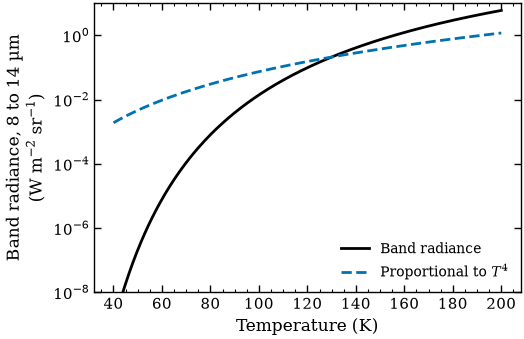

In [3]:
for T in (90.0, 110.0, 130.0):
    n = np.log(band.radiance(1.01 * T) / band.radiance(T / 1.01)) / (2 * np.log(1.01))
    print(f"{T:.0f} K: band radiance {band.radiance(T):.3e} W m-2 sr-1, d ln L / d ln T = {n:.1f}")

T = np.linspace(40.0, 200.0, 400)
fig, ax = plt.subplots(figsize=(plots.COLUMN_W * 1.5, 3.4), constrained_layout=True)
ax.semilogy(T, band.radiance(T), label="Band radiance")
ax.semilogy(T, band.radiance(130.0) * (T / 130.0) ** 4, label="Proportional to $T^4$")
ax.set_ylim(1e-8, 10)
ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Band radiance, 8 to 14 µm\n(W m$^{-2}$ sr$^{-1}$)")
ax.legend(loc="lower right")
plt.show()

## 3. The visible disk

The hemisphere that faces Earth at 12:00 UTC and shortly after the eclipse, as surface temperature
(top) and as band brightness temperature (bottom). The band brightness temperature of a face is the
temperature of a blackbody with the face's band radiance, thermal and reflected, which is what an
imager records. Faces turned away from Earth have none, and the vertex average below ignores them.

12:00 UTC: surface 41.9 to 133.2 K, band 61.1 to 131.8 K
21:10 UTC: surface 40.8 to 118.2 K, band 54.9 to 117.3 K


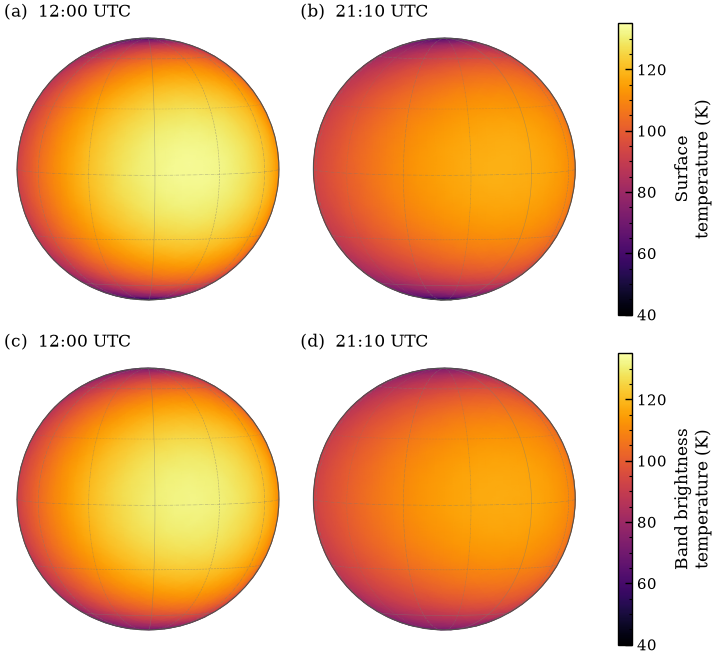

In [4]:
def vertex_values(mesh, face_values):
    ok = np.isfinite(face_values)
    total = plots.vertex_values_from_faces(mesh["faces"], np.where(ok, face_values, 0.0),
                                           mesh["n_vertices"])
    count = plots.vertex_values_from_faces(mesh["faces"], ok.astype(float), mesh["n_vertices"])
    return np.where(count > 0, total / np.maximum(count, 1e-12), np.nan)

fig, axes = plt.subplots(2, 2, figsize=(plots.DOUBLE_W, 6.6), constrained_layout=True)
for col, (run, utc, title) in enumerate(((orbit_run, "2025-01-01T12:00:00", "12:00 UTC"),
                                         (eclipse_run, "2025-01-01T21:10:00", "21:10 UTC"))):
    geom, T, em = observe_band(run, utc)
    mesh = run.mesh
    art_t = plots.globe(axes[0, col], mesh["vertices"], mesh["faces"],
                        plots.vertex_values_from_faces(mesh["faces"], T, mesh["n_vertices"]),
                        geom.sub_observer_lat, geom.sub_observer_lon,
                        norm=plt.Normalize(40, 135))
    art_b = plots.globe(axes[1, col], mesh["vertices"], mesh["faces"],
                        vertex_values(mesh, em.face_tb_k), geom.sub_observer_lat,
                        geom.sub_observer_lon, norm=plt.Normalize(40, 135))
    vis = em.face_mu > 0
    print(f"{title}: surface {T[vis].min():.1f} to {T[vis].max():.1f} K, "
          f"band {np.nanmin(em.face_tb_k):.1f} to {np.nanmax(em.face_tb_k):.1f} K")
plots.colorbar(fig, art_t, axes[0, :], label="Surface\ntemperature (K)")
plots.colorbar(fig, art_b, axes[1, :], label="Band brightness\ntemperature (K)")
plots.panel_labels(axes, titles=["12:00 UTC", "21:10 UTC"] * 2)
plt.show()

## 4. The disk brightness temperature through the orbit and the eclipse

Every hour through the orbit (from the one-orbit simulation) and every three minutes through the
eclipse (from the one-minute simulation). Times when Jupiter hides Europa are skipped. The mean
surface temperature of the visible disk, weighted by projected area, is drawn for comparison.
The dark gray band marks the occultation, when Europa is behind Jupiter as seen from Earth. The
light gray band marks the eclipse, when Europa is in Jupiter's shadow. The hatched band marks the
transit, when Europa passes in front of Jupiter and is still visible.

orbit: T_b 100.3 to 119.5 K, 2.0 to 4.0 K above the mean surface temperature
eclipse: T_b from 99.8 K in the shadow to 115.1 K at 22.95 h


occultation 17.22 to 19.84 h
transit 60.25 to 62.84 h
eclipse 18.48 to 21.11 h


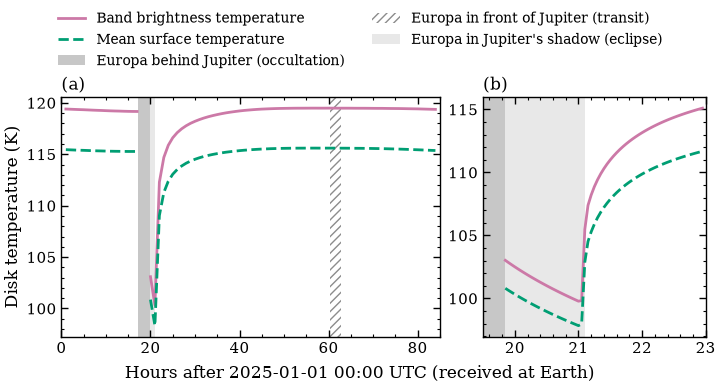

In [5]:
start = np.datetime64("2025-01-01T00:00:00")

def series(run, minutes):
    rows = []
    for m in minutes:
        utc = str(start + np.timedelta64(int(m), "m"))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            geom = observe.observer_geometry(run, utc, observer="EARTH")
        if "occulted" in geom.occultation:       # Jupiter hides Europa
            continue
        em = observe.band_emission(run, observe.temperature_at(run, geom), geom, band=band,
                                   emissivity=EMISSIVITY,
                                   direct_solar=observe.temperature_at(run, geom, "direct_solar"))
        rows.append((geom.utc_observed, m / 60, em.tb_k, em.mean_temperature_k,
                     em.reflected_fraction_disk, em.flux_w_m2))
    return rows

orbit = series(orbit_run, np.arange(60, 5100, 60))
egress = series(eclipse_run, np.arange(1170, 1380, 3))
o = np.array([r[1:] for r in orbit])
e = np.array([r[1:] for r in egress])
print(f"orbit: T_b {o[:, 1].min():.1f} to {o[:, 1].max():.1f} K, "
      f"{(o[:, 1] - o[:, 2]).min():.1f} to {(o[:, 1] - o[:, 2]).max():.1f} K above the mean surface temperature")
print(f"eclipse: T_b from {e[:, 1].min():.1f} K in the shadow to {e[-1, 1]:.1f} K at {e[-1, 0]:.2f} h")

def with_gaps(d, step_h):
    """Insert a row of NaN wherever Jupiter hid Europa, so the curves break there."""
    rows = [d[0]]
    for prev, row in zip(d[:-1], d[1:]):
        if row[0] - prev[0] > 1.5 * step_h:
            rows.append(np.full(d.shape[1], np.nan))
        rows.append(row)
    return np.array(rows)

import spiceypy as sp

def hidden(front, back, observer, hours=86.0):
    """Intervals (hours after start) in which `front` hides any part of `back`
    as seen from `observer`, at the time the light reaches `observer`."""
    t0 = sp.str2et(str(start))
    window, found = sp.cell_double(2), sp.cell_double(40)
    sp.wninsd(t0, t0 + hours * 3600.0, window)
    sp.gfoclt("ANY", front, "ELLIPSOID", f"IAU_{front}", back, "ELLIPSOID", f"IAU_{back}",
              "CN", observer, 60.0, window, found)
    return [((a - t0) / 3600, (b - t0) / 3600)
            for a, b in (sp.wnfetd(found, i) for i in range(sp.wncard(found)))]

# The metakernel lists its kernels relative to the repository root.
import os
here = os.getcwd()
os.chdir(ROOT)
sp.furnsh("data/kernels/europa.tm")
os.chdir(here)
# The shadow is found as seen from Europa and moved to the time its light reaches Earth.
light_h = sp.spkpos("EUROPA", sp.str2et(str(start)), "J2000", "CN", "EARTH")[1] / 3600
events = {"occultation": hidden("JUPITER", "EUROPA", "EARTH"),
          "transit": hidden("EUROPA", "JUPITER", "EARTH"),
          "eclipse": [(a + light_h, b + light_h) for a, b in hidden("JUPITER", "SUN", "EUROPA")]}
names = {"occultation": "Europa behind Jupiter (occultation)",
         "eclipse": "Europa in Jupiter's shadow (eclipse)",
         "transit": "Europa in front of Jupiter (transit)"}
for kind, spans in events.items():
    print(kind, ", ".join(f"{a:.2f} to {b:.2f} h" for a, b in spans))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(plots.DOUBLE_W, 3.9), layout="constrained",
                               gridspec_kw={"width_ratios": [1.7, 1.0]})
for ax, d in ((ax1, with_gaps(o, 1.0)), (ax2, with_gaps(e, 0.05))):
    ax.plot(d[:, 0], d[:, 1], **plots.STYLES["brightness"], label="Band brightness temperature")
    ax.plot(d[:, 0], d[:, 2], **plots.STYLES["surface"], label="Mean surface temperature")
    for kind, spans in events.items():
        for a, b in spans:
            ax.axvspan(a, b, **plots.SHADES[kind], label=names[kind])
ax1.set_xlim(0, 85)
ax2.set_xlim(19.5, 23.0)
fig.supxlabel("Hours after 2025-01-01 00:00 UTC (received at Earth)",
              fontsize=plt.rcParams["axes.labelsize"])
ax1.set_ylabel("Disk temperature (K)")
fig.legend(*ax1.get_legend_handles_labels(), loc="outside upper center", ncol=2)
plots.panel_labels([ax1, ax2])
plt.show()

## 5. The fit to synthetic observations

`examples/python/fit_europa_thermal_infrared.py` made synthetic observations from a simulation
with thermal inertia 70 and emissivity 0.92, with 5 percent noise, and fitted them with a grid of
simulations at the Bond albedo of 0.5. It saved its results in `fit_results.npz`. The contours
are the regions of 68 and 95 percent confidence for the two parameters, with the rotation times
only and with the eclipse times added. The fitted values are conditional on the Bond albedo of 0.5.

best fit with all observations: thermal inertia 68.6, emissivity 0.933 (true 70 and 0.92)


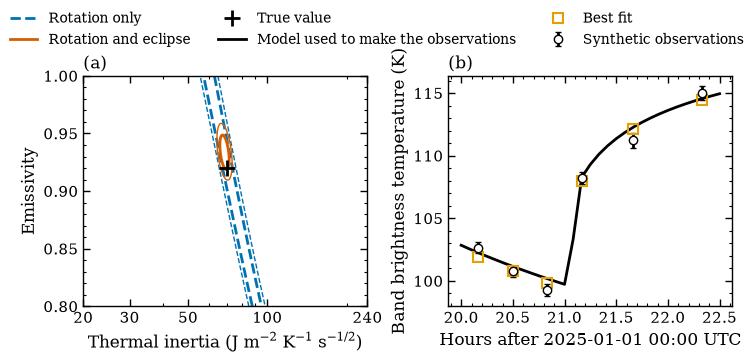

In [6]:
from matplotlib.ticker import NullFormatter, ScalarFormatter

fit = np.load(ROOT / "output" / "europa_tir_fit" / "fit_results.npz")
print(f"best fit with all observations: thermal inertia {float(fit['best_ti']):.1f}, "
      f"emissivity {float(fit['best_emissivity']):.3f} "
      f"(true {float(fit['true_ti']):g} and {float(fit['true_emissivity']):g})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(plots.DOUBLE_W, 3.6), layout="constrained")
for key, label, color, style in (("chi2_rotation", "Rotation only", plots.BLUE, "--"),
                                 ("chi2_all", "Rotation and eclipse", plots.VERMILLION, "-")):
    c2 = fit[key]
    ax1.contour(fit["ti_fine"], fit["eps_fine"], c2 - c2.min(), levels=[2.30, 6.18],
                colors=color, linewidths=[2.0, 1.0], linestyles=style)
    ax1.plot([], [], style, color=color, label=label)
ax1.plot([fit["true_ti"]], [fit["true_emissivity"]], "+", ms=12, mew=2, color=plots.BLACK,
         label="True value")
ax1.set_xscale("log")
ax1.set_xticks([20, 30, 50, 100, 240])
ax1.xaxis.set_major_formatter(ScalarFormatter())
ax1.xaxis.set_minor_formatter(NullFormatter())
ax1.set_xlabel(r"Thermal inertia (J m$^{-2}$ K$^{-1}$ s$^{-1/2}$)")
ax1.set_ylabel("Emissivity")

n = int(fit["n_rotation"])
ax2.plot(fit["curve_eclipse_hours"], fit["curve_eclipse_tb"], **plots.STYLES["model"],
         label="Model used to make the observations")
ax2.errorbar(fit["hours"][n:], fit["tb_obs"][n:], yerr=fit["tb_err"][n:],
             **plots.STYLES["observed"], capsize=2, label="Synthetic observations")
ax2.plot(fit["hours"][n:], fit["tb_best"][n:], "s", ms=7, mfc="none", mew=1.5,
         color=plots.ORANGE, label="Best fit")
ax2.set_xlabel("Hours after 2025-01-01 00:00 UTC")
ax2.set_ylabel("Band brightness temperature (K)")
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles=handles, loc="outside upper center", ncol=3)
plots.panel_labels([ax1, ax2])
plt.show()

## 6. A table of the disk brightness temperature

The disk quantities of section 4, one row per observation time, for plotting elsewhere or for
comparison with a measurement.

In [7]:
table = ROOT / "output" / "europa_tir_disk_series.csv"
with open(table, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["utc_observed", "simulation", "tb_k", "mean_temperature_k",
                "reflected_fraction_disk", "flux_w_m2"])
    for name, rows in (("orbit", orbit), ("eclipse", egress)):
        for utc, hours, tb, tmean, refl, flux in rows:
            w.writerow([utc, name, f"{tb:.3f}", f"{tmean:.3f}", f"{refl:.5f}", f"{flux:.5e}"])
print(f"wrote {table.relative_to(ROOT)}: {len(orbit) + len(egress)} rows")

wrote output/europa_tir_disk_series.csv: 145 rows
